# SmartProp Rwanda: House Price Prediction Model

## Project goal
Build a model that estimates the sale price of a house from its land, building and location data, and returns a price range and the reasons behind the estimate.

## Data
`kc_house_data`: about 21,600 house sales in King County, USA (2014-2015). It is **practice data** used to learn the full pipeline. The same notebook will later be run on Rwandan data.

## Target and approach
- **Target:** `price` (the real sale price)
- **Approach:** supervised regression. The model learns from houses with known prices and predicts the price of new houses.
- **Test method:** the test set contains whole areas the model has never seen, to simulate valuing a house in a new place.

## 1. Setup and settings
**What we want to do:** import the libraries and put every setting in one place.

**Why:** if a setting such as the target column or the area column must change (for example when we switch to Rwandan data), we change it here once and nothing else breaks.

**Check:** no output. If an import error appears, install the missing library with `pip install`.

In [3]:
import glob, json, warnings
from pathlib import Path
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
import joblib, shap

from sklearn.model_selection import GroupShuffleSplit, GroupKFold, cross_val_predict, RandomizedSearchCV
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.dummy import DummyRegressor
from sklearn.linear_model import Ridge
from sklearn.ensemble import RandomForestRegressor
from xgboost import XGBRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid")

SEED = 42
TARGET = "price"        # what we predict
GROUP_COL = "zipcode"   # area column (use village or sector for Rwanda)
REF_YEAR = 2015         # the data covers 2014-2015
MODEL_DIR = Path("models"); MODEL_DIR.mkdir(exist_ok=True)

## 2. Load the data
**What we want to do:** read the CSV file into a table (DataFrame) and look at the first rows.

**Why:** we must see what the data contains before modelling: the column names, the size of the table, and the type of each value.

**Check:** about 21,600 rows and 21 columns, including a `price` column.

In [5]:
path = glob.glob("**/kc_house_data*.csv", recursive=True)
df_raw = pd.read_csv(path[0])
print(df_raw.shape)
df_raw.head()

(21613, 18)


,id,date,price,bedrooms,bathrooms,sqft_living,sqft_lot,floors,waterfront,view,condition,grade,sqft_above,sqft_basement,yr_built,yr_renovated,sqft_living15,sqft_lot15
0,7129300520,20141013T000000,221900.0,3,1.00,1180,5650,1.0,standard,0,3,7,1180,0,1955,0,1340,5650
1,6414100192,20141209T000000,538000.0,3,2.25,2570,7242,2.0,standard,0,3,7,2170,400,1951,1991,1690,7639
2,5631500400,20150225T000000,180000.0,2,1.00,770,10000,1.0,standard,0,3,6,770,0,1933,0,2720,8062
3,2487200875,20141209T000000,604000.0,4,3.00,1960,5000,1.0,standard,0,5,7,1050,910,1965,0,1360,5000
4,1954400510,20150218T000000,510000.0,3,2.00,1680,8080,1.0,standard,0,3,8,1680,0,1987,0,1800,7503


## 3. Check data quality
**What we want to do:** look for missing values, duplicate rows, wrong data types and impossible numbers.

**Why:** a model learns whatever it is given. If the data contains errors, the model learns the errors. This is the cheapest place to find problems.

**Check:** the missing values per column, the number of duplicates, and the minimum and maximum of each column (for example a house with 33 bedrooms).

In [6]:
df_raw.info()
print("Duplicates:", df_raw.duplicated().sum())
df_raw.describe().T.round(2)

<class 'pandas.DataFrame'>
RangeIndex: 21613 entries, 0 to 21612
Data columns (total 18 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   id             21613 non-null  int64  
 1   date           21613 non-null  str    
 2   price          21613 non-null  float64
 3   bedrooms       21613 non-null  int64  
 4   bathrooms      21613 non-null  float64
 5   sqft_living    21613 non-null  int64  
 6   sqft_lot       21613 non-null  int64  
 7   floors         21613 non-null  float64
 8   waterfront     21613 non-null  str    
 9   view           21613 non-null  int64  
 10  condition      21613 non-null  int64  
 11  grade          21613 non-null  int64  
 12  sqft_above     21613 non-null  int64  
 13  sqft_basement  21613 non-null  int64  
 14  yr_built       21613 non-null  int64  
 15  yr_renovated   21613 non-null  int64  
 16  sqft_living15  21613 non-null  int64  
 17  sqft_lot15     21613 non-null  int64  
dtypes: float64(3), in

,count,mean,std,min,25%,50%,75%,max
id,21613.0,4.580302e+09,2.876566e+09,1000102.0,2.123049e+09,3.904930e+09,7.308900e+09,9.900000e+09
price,21613.0,5.400881e+05,3.671272e+05,75000.0,3.219500e+05,4.500000e+05,6.450000e+05,7.700000e+06
bedrooms,21613.0,3.370000e+00,9.300000e-01,0.0,3.000000e+00,3.000000e+00,4.000000e+00,3.300000e+01
bathrooms,21613.0,2.110000e+00,7.700000e-01,0.0,1.750000e+00,2.250000e+00,2.500000e+00,8.000000e+00
sqft_living,21613.0,2.079900e+03,9.184400e+02,290.0,1.427000e+03,1.910000e+03,2.550000e+03,1.354000e+04
sqft_lot,21613.0,1.510697e+04,4.142051e+04,520.0,5.040000e+03,7.618000e+03,1.068800e+04,1.651359e+06
floors,21613.0,1.490000e+00,5.400000e-01,1.0,1.000000e+00,1.500000e+00,2.000000e+00,3.500000e+00
view,21613.0,2.300000e-01,7.700000e-01,0.0,0.000000e+00,0.000000e+00,0.000000e+00,4.000000e+00
condition,21613.0,3.410000e+00,6.500000e-01,1.0,3.000000e+00,3.000000e+00,4.000000e+00,5.000000e+00
grade,21613.0,7.660000e+00,1.180000e+00,1.0,7.000000e+00,7.000000e+00,8.000000e+00,1.300000e+01


## 4. Clean the data
**What we want to do:** remove duplicate rows and rows with impossible values, using clear written rules.

**Why:** each rule is counted and printed so we can explain exactly what was removed and why. We remove only clear errors, never a house just because its price is high.

**Check:** only a handful of rows are removed. If many rows disappear, a rule is too strict.

In [7]:
df = df_raw.drop_duplicates().copy()

rules = {
    "price above 0":        df[TARGET] > 0,
    "living area above 0":  df["sqft_living"] > 0,
    "bedrooms 15 or fewer": df["bedrooms"] <= 15,
    "land area above 0":    df["sqft_lot"] > 0,
}
keep = pd.Series(True, index=df.index)
for name, ok in rules.items():
    print(f"{name:<22} removes {(~ok).sum()} rows")
    keep &= ok
df = df[keep].reset_index(drop=True)
print("Rows left:", len(df))

price above 0          removes 0 rows
living area above 0    removes 0 rows
bedrooms 15 or fewer   removes 1 rows
land area above 0      removes 0 rows
Rows left: 21612


## 5. Explore the data (EDA)
**What we want to do:** draw charts to understand the target and the main drivers of price.

**Why:** exploration tells us how to prepare the target and which features matter, and it gives us findings for the report.

**What we look for:**
- **Price distribution:** it is skewed to the right, so we will train on `log(price)`.
- **Correlations:** which columns move with price (size and grade are strong).
- **Map of prices:** where expensive houses are. Location clearly matters, so the model gets latitude and longitude.

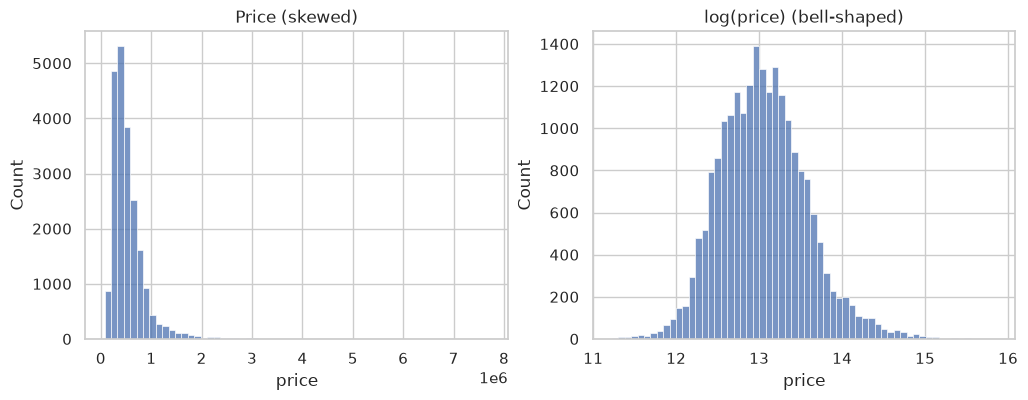

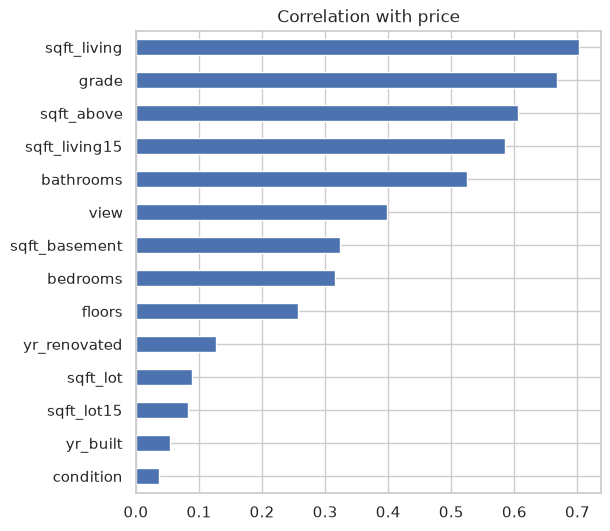

KeyError: 'long'

<Figure size 600x600 with 0 Axes>

In [9]:
# 5.1 the target
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
sns.histplot(df[TARGET], bins=60, ax=ax[0]); ax[0].set_title("Price (skewed)")
sns.histplot(np.log1p(df[TARGET]), bins=60, ax=ax[1]); ax[1].set_title("log(price) (bell-shaped)")
plt.show()

# 5.2 what moves with price
corr = df.drop(columns="id").corr(numeric_only=True)[TARGET].drop(TARGET).sort_values()
corr.plot.barh(figsize=(6, 6), title="Correlation with price"); plt.show()

# 5.3 location
plt.figure(figsize=(6, 6))
plt.scatter(df["long"], df["lat"], c=np.log1p(df[TARGET]), s=3, cmap="viridis")
plt.colorbar(label="log(price)"); plt.title("Where expensive houses are"); plt.show()

## 6. Create features
**What we want to do:** choose the columns the model will use and create new ones that describe the house better (house age, renovated yes/no, years since renovation, has basement, share of the land that is built, total rooms).

**Why:** raw columns are not always the clearest signal. For example, "built in 1985" becomes "30 years old". We create all features in **one function** so that training and the future API use exactly the same steps.

**Columns we leave out:** `id` (only an identifier), `date` (the data covers one year), `zipcode` (used only to split the data, because location is already given by latitude and longitude).

In [10]:
BASE_FEATURES = ["bedrooms", "bathrooms", "sqft_living", "sqft_lot", "floors", "waterfront", "view",
                 "condition", "grade", "sqft_above", "sqft_basement", "yr_built", "lat", "long",
                 "sqft_living15", "sqft_lot15"]
ENGINEERED = ["house_age", "is_renovated", "years_since_reno", "has_basement", "living_to_lot", "total_rooms"]
FEATURES = BASE_FEATURES + ENGINEERED
RAW_INPUTS = BASE_FEATURES + ["yr_renovated"]

def add_features(d):
    d = d.copy()
    d["house_age"]        = (REF_YEAR - d["yr_built"]).clip(lower=0)
    d["is_renovated"]     = (d["yr_renovated"] > 0).astype(int)
    d["years_since_reno"] = np.where(d["yr_renovated"] > 0, (REF_YEAR - d["yr_renovated"]).clip(lower=0), d["house_age"])
    d["has_basement"]     = (d["sqft_basement"] > 0).astype(int)
    d["living_to_lot"]    = d["sqft_living"] / d["sqft_lot"].replace(0, np.nan)
    d["total_rooms"]      = d["bedrooms"] + d["bathrooms"]
    return d

df_fe  = add_features(df)
X      = df_fe[FEATURES]
y      = df_fe[TARGET]
y_log  = np.log1p(y)
groups = df_fe[GROUP_COL]
X.head()

KeyError: "['lat', 'long'] not in index"

## 7. Split into train and test (by area)
**What we want to do:** keep 20% of the **areas** aside as a final test set. The model trains on the rest.

**Why:** a random split puts houses from the same street in both parts, so the model has already "seen" the neighbourhood and the score looks better than it is. Splitting by area tests what we really need: valuing a house in a place the model has not seen. The test set stays closed until Step 11.

**Check:** the train and test areas do not overlap (the code asserts this).

In [11]:
splitter = GroupShuffleSplit(n_splits=1, test_size=0.2, random_state=SEED)
train_idx, test_idx = next(splitter.split(X, y_log, groups))

X_train, X_test = X.iloc[train_idx], X.iloc[test_idx]
y_train, y_test = y.iloc[train_idx], y.iloc[test_idx]
ylog_train, ylog_test = y_log.iloc[train_idx], y_log.iloc[test_idx]
g_train, g_test = groups.iloc[train_idx], groups.iloc[test_idx]

assert set(g_train).isdisjoint(set(g_test)), "Test areas leaked into training!"
print(len(X_train), "train houses |", len(X_test), "test houses in unseen areas")

NameError: name 'X' is not defined

## 8. Compare models with cross-validation
**What we want to do:** train four models (baseline, Ridge, Random Forest, XGBoost) and compare their errors on the training data, using five folds that each test on unseen areas.

**Why:** we do not know in advance which model is best for this data, so we compare them fairly. The **baseline** (always guess the median price) is the minimum to beat. A model that does not beat it clearly has a problem.

**How we measure:** MAE and RMSE (average error in money), R², MAPE (average error in %), and the share of houses predicted within 10% and 20% of the real price. We train on `log(price)` but report in money, because that is what people understand.

**Check:** the tree models usually beat Ridge. Put this table in the report.

In [12]:
def evaluate(ylog_true, ylog_pred):
    yt, yp = np.expm1(ylog_true), np.expm1(ylog_pred)       # back to money
    ape = np.abs(yp - yt) / yt
    return {"MAE": mean_absolute_error(yt, yp),
            "RMSE": np.sqrt(mean_squared_error(yt, yp)),
            "R2": r2_score(yt, yp),
            "MAPE_%": 100 * ape.mean(),
            "within_10%": 100 * (ape <= .10).mean(),
            "within_20%": 100 * (ape <= .20).mean()}

imp = lambda: SimpleImputer(strategy="median")
models = {
    "baseline_median": Pipeline([("prep", imp()), ("model", DummyRegressor(strategy="median"))]),
    "ridge":           Pipeline([("prep", imp()), ("scale", StandardScaler()), ("model", Ridge(alpha=1.0))]),
    "random_forest":   Pipeline([("prep", imp()), ("model", RandomForestRegressor(n_estimators=300, min_samples_leaf=2, n_jobs=-1, random_state=SEED))]),
    "xgboost":         Pipeline([("prep", imp()), ("model", XGBRegressor(n_estimators=600, learning_rate=0.05, max_depth=5,
                                                                      subsample=0.8, colsample_bytree=0.8, n_jobs=-1, random_state=SEED))]),
}

gkf = GroupKFold(n_splits=5)
oof, rows = {}, []
for name, pipe in models.items():
    oof[name] = cross_val_predict(pipe, X_train, ylog_train, cv=gkf, groups=g_train)
    rows.append({"model": name, **evaluate(ylog_train, oof[name])})

cv_table = pd.DataFrame(rows).set_index("model").sort_values("MAE").round(2)
cv_table

NameError: name 'X_train' is not defined

## 9. Tune the best model
**What we want to do:** try 15 random combinations of XGBoost settings (number of trees, depth, learning rate and others) and keep the best one.

**Why:** default settings are rarely the best. Tuning uses only the training data, so the test set stays untouched.

**Check:** the tuned model is usually only slightly better than default XGBoost. That is normal. The bigger gains come from better data and features. This cell takes a few minutes.

In [13]:
param_dist = {
    "model__n_estimators":     [300, 500, 800, 1200],
    "model__learning_rate":    [0.02, 0.03, 0.05, 0.08],
    "model__max_depth":        [3, 4, 5, 6, 7],
    "model__min_child_weight": [1, 3, 5],
    "model__subsample":        [0.7, 0.8, 0.9, 1.0],
    "model__colsample_bytree": [0.6, 0.8, 1.0],
    "model__reg_lambda":       [0.5, 1, 3, 10],
}
search = RandomizedSearchCV(models["xgboost"], param_dist, n_iter=15,
                            scoring="neg_root_mean_squared_error",
                            cv=GroupKFold(n_splits=5), random_state=SEED, verbose=1)
search.fit(X_train, ylog_train, groups=g_train)
best_model = search.best_estimator_
print(search.best_params_)

oof["xgboost_tuned"] = cross_val_predict(best_model, X_train, ylog_train, cv=gkf, groups=g_train)
cv_table.loc["xgboost_tuned"] = pd.Series(evaluate(ylog_train, oof["xgboost_tuned"])).round(2)
cv_table.sort_values("MAE")

NameError: name 'X_train' is not defined

## 10. Build the price range
**What we want to do:** use the model's past errors to calculate a low and a high price around each estimate (an 80% range).

**Why:** one number looks more certain than it is. A range tells the owner how much the estimate can vary, which is more honest and more useful for decisions.

**Check:** the range is shown as a percentage around the estimate, for example about -30% to +40%.

In [14]:
resid = ylog_train - oof["xgboost_tuned"]          # past errors in log units
q_low, q_high = np.quantile(resid, [0.10, 0.90])
print(f"Range: {np.expm1(q_low):+.0%} to {np.expm1(q_high):+.0%} around the estimate")

NameError: name 'ylog_train' is not defined

## 11. Final test on unseen areas
**What we want to do:** measure the final model once, on the test areas it has never seen.

**Why:** this is the honest result we report. We never tune the model after seeing it, otherwise the test is no longer fair.

**What we check:**
- The same metrics as in Step 8, now on unseen areas.
- **Range coverage:** the 80% range should contain the real price for about 80% of test houses. If it is much lower, widen the range (use `[0.05, 0.95]` in Step 10).
- **Error by price band:** is the model worse for cheap or for expensive houses? We must state this limit to users.

In [ ]:
pred_log = best_model.predict(X_test)
print(pd.Series(evaluate(ylog_test, pred_log)).round(2))

results = pd.DataFrame({"actual": y_test.values,
                        "estimate": np.expm1(pred_log),
                        "low": np.expm1(pred_log + q_low),
                        "high": np.expm1(pred_log + q_high)}, index=X_test.index)
coverage = ((results.actual >= results.low) & (results.actual <= results.high)).mean()
print(f"80% range contained the real price for {coverage:.0%} of test houses")

# error by price band
err = (results.estimate - results.actual).abs() / results.actual * 100
band = pd.qcut(results.actual, 5, labels=["lowest", "low", "middle", "high", "highest"])
err.groupby(band).mean().plot.bar(title="Average % error by price band"); plt.show()

## 12. Explain the model with SHAP
**What we want to do:** measure how much each feature pushes the estimate up or down.

**Why:** a valuation affects loans, taxes and sales, so users must see why the model gives an estimate. It also checks the model: size, build quality and location should be the main drivers. If a strange feature dominates, there may be a data leak.

**How to read it:** values are in log-price units, so +0.10 means about 10% higher.

In [ ]:
model_step = best_model.named_steps["model"]
X_test_t = pd.DataFrame(best_model.named_steps["prep"].transform(X_test), columns=FEATURES, index=X_test.index)
sample = X_test_t.sample(min(2000, len(X_test_t)), random_state=SEED)

sv = shap.TreeExplainer(model_step)(sample)
shap.plots.bar(sv, max_display=15)        # which features matter most
shap.plots.beeswarm(sv, max_display=15)   # how each feature pushes price up or down

## 13. Save the model and its settings
**What we want to do:** save the trained model together with the feature list, the default values for missing inputs, the price range, the test metrics and the version name.

**Why:** an API needs more than the model file. Without the feature order and the defaults it would give wrong answers. A version name tells us which model produced each estimate.

In [ ]:
raw_defaults = df[RAW_INPUTS].median().to_dict()
raw_defaults["yr_renovated"] = 0
raw_defaults["sqft_basement"] = 0

meta = {
    "model_name": "kc_price_xgb_v1",
    "features": FEATURES,
    "raw_inputs": RAW_INPUTS,
    "required_inputs": ["sqft_living", "sqft_lot", "bedrooms", "bathrooms", "lat", "long", "yr_built", "grade", "condition"],
    "raw_defaults": {k: float(v) for k, v in raw_defaults.items()},
    "interval": {"log_low": float(q_low), "log_high": float(q_high), "label": "80% range"},
    "test_metrics": {k: round(float(v), 3) for k, v in evaluate(ylog_test, pred_log).items()},
}
joblib.dump(best_model, MODEL_DIR / "kc_price_xgb_v1.joblib")
(MODEL_DIR / "kc_price_xgb_v1_meta.json").write_text(json.dumps(meta, indent=2))
print("Saved:", sorted(p.name for p in MODEL_DIR.iterdir()))

## 14. Prediction function (the future API)
**What we want to do:** write one function that takes a house as a dictionary and returns the estimate, the 80% range, the top five reasons, the model version and a disclaimer.

**Why:** this function is the core of the API. It also protects the model: it rejects inputs that miss required fields, fills optional fields with defaults, and builds the features exactly as in training.

**Check:** try a normal house, then remove a required field and confirm that it returns a clear error.

In [ ]:
def predict_price(house: dict):
    model = joblib.load(MODEL_DIR / "kc_price_xgb_v1.joblib")
    m = json.loads((MODEL_DIR / "kc_price_xgb_v1_meta.json").read_text())

    missing = [k for k in m["required_inputs"] if k not in house]
    if missing:
        raise ValueError(f"Missing required inputs: {missing}")

    row = {**m["raw_defaults"], **house}                       # fill optional fields
    X_new = add_features(pd.DataFrame([row]))[m["features"]]
    p = float(model.predict(X_new)[0])

    Xt = pd.DataFrame(model.named_steps["prep"].transform(X_new), columns=m["features"])
    sv_new = shap.TreeExplainer(model.named_steps["model"])(Xt)
    top = np.argsort(-np.abs(sv_new.values[0]))[:5]
    reasons = [{"feature": m["features"][j], "effect_%": round(float(np.expm1(sv_new.values[0][j]) * 100), 1)} for j in top]

    return {"estimate": round(float(np.expm1(p)), -2),
            "low":  round(float(np.expm1(p + m["interval"]["log_low"])), -2),
            "high": round(float(np.expm1(p + m["interval"]["log_high"])), -2),
            "range_label": m["interval"]["label"],
            "top_reasons": reasons,
            "model_version": m["model_name"],
            "disclaimer": "AI estimate for guidance. Not a certified valuation."}

predict_price({"sqft_living": 1800, "sqft_lot": 6000, "bedrooms": 3, "bathrooms": 2,
               "lat": 47.55, "long": -122.25, "yr_built": 1985, "grade": 7, "condition": 3})